### 5. Explore the assumption of star-formation history and DCO compute rates at one single metallicity

#### 1. Creating the Synthetic Population DataFrame

In [1]:
import os
from posydon.popsyn.synthetic_population import Population
from posydon.config import PATH_TO_POSYDON_DATA

In [4]:
pop = Population('../Generated_Tuto_Data/1e+00_Zsun_population.h5')

pop.history.head(25)

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
0,detached,ZAMS,0.000000e+00,982.224383,0.0,NaN,initial_cond,0.000000,H-rich_Core_H_burning,11.389235,...,NaN,NaN,NaN,NaN,0.715500,2.703000e-01,NaN,NaN,NaN,NaN
0,detached,CC1,2.288689e+07,3383.248305,0.0,-45.303133,step_HMS_HMS,2.966677,H-rich_Core_C_depleted,4.429219,...,2.608503,0.207269,0.000000,0.000000,0.028811,5.013443e-01,0.702720,0.283207,0.302342,27.160166
0,disrupted,NaN,2.288689e+07,NaN,NaN,NaN,step_SN,0.000695,NS,1.399559,...,2.608503,0.207269,0.000000,0.000000,0.028811,5.013443e-01,0.702720,0.283207,0.302342,27.160166
0,disrupted,CC2,2.452158e+07,NaN,NaN,NaN,step_disrupted,3.779525,NS,1.399559,...,3.786868,NaN,2.457813,0.057436,0.000000,1.756680e-13,0.688253,0.297473,0.001547,1.324030
0,disrupted,NaN,2.452158e+07,NaN,NaN,NaN,step_SN,0.000529,NS,1.399559,...,NaN,NaN,2.457813,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
0,disrupted,END,2.452158e+07,NaN,NaN,NaN,step_end,0.000051,NS,1.399559,...,NaN,NaN,2.457813,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
1,detached,ZAMS,0.000000e+00,745.251114,0.0,NaN,initial_cond,0.000000,H-rich_Core_H_burning,9.591084,...,NaN,NaN,NaN,NaN,0.715500,2.703000e-01,NaN,NaN,NaN,NaN
1,detached,CC1,3.132844e+07,1405.497677,0.0,-90.325591,step_HMS_HMS,0.359742,H-rich_Core_C_depleted,3.159656,...,0.000000,0.000000,0.000000,0.000000,0.561358,4.247369e-01,0.712456,0.273225,0.848483,15.727920
1,disrupted,NaN,3.132844e+07,NaN,NaN,NaN,step_SN,0.000495,NS,1.277584,...,0.000000,0.000000,0.000000,0.000000,0.561358,4.247369e-01,0.712456,0.273225,0.848483,15.727920


In [11]:
pop.history.select(where='index==2', columns = ['state', 'time', 'S1_state', 'S2_state', 'event'])

,state,time,S1_state,S2_state,event
binary_index,,,,,
2,detached,0.000000e+00,H-rich_Core_H_burning,H-rich_Core_H_burning,ZAMS
2,detached,5.373704e+07,stripped_He_Core_He_depleted,H-rich_Core_H_burning,CC1
2,detached,5.373704e+07,WD,H-rich_Core_H_burning,NaN
2,RLO2,1.390695e+08,WD,H-rich_Shell_H_burning,oRLO2
2,RLO2,1.390900e+08,WD,H-rich_Shell_H_burning,oCE2
2,merged,1.390900e+08,WD,H-rich_Shell_H_burning,oMerging2
2,merged,1.436986e+08,massless_remnant,H-rich_Core_He_depleted,CC2
2,merged,1.436986e+08,massless_remnant,WD,NaN
2,merged,1.436986e+08,massless_remnant,WD,END


We need to select only BBH at 1 $Z_{\odot}$ from the population list. Then calculate the transient population. 

In [ ]:
# read the relevant data in one go
# (faster than reading it in chunks, but requires more memory)
tmp_data = pop.history.select(columns=['S1_state', 'S2_state', 'event'])
# Selection of S1 being a BH
S1_state = tmp_data['S1_state'] == 'BH'
# Selection of S2 being a BH
S2_state = tmp_data['S2_state'] == 'BH'
# Selection of the binary system being in contact during the double CO phase.
state = tmp_data['event'] == 'CO_contact'
indices = tmp_data.index
del tmp_data
mask = S1_state & S2_state & state
selected_indices = indices[mask].to_list()
print(f'Number of systems: {len(selected_indices)}')

# set overwrite to False to add to the file
pop.export_selection(selected_indices, '../Generated_Tuto_Data/Zsun_BBH_contact.h5', overwrite = False)

Number of systems: 1
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [14]:
from posydon.popsyn.synthetic_population import Population
pop = Population('../Generated_Tuto_Data/Zsun_BBH_contact.h5')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [15]:
pop.history

,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
0,detached,ZAMS,0.000000e+00,6.316024e+01,0.000000,NaN,initial_cond,0.000000,H-rich_Core_H_burning,29.830218,...,NaN,NaN,NaN,NaN,0.715500,2.703000e-01,NaN,NaN,NaN,NaN
0,detached,CC1,6.924045e+06,1.491706e+02,0.000000,-99.000000,step_HMS_HMS,0.147928,stripped_He_Core_C_depleted,10.262995,...,0.341316,0.026509,0.286132,0.010963,0.035856,9.372818e-01,6.949276e-01,0.271629,0.028521,0.370167
0,detached,NaN,6.924045e+06,9.873719e+01,0.358690,NaN,step_SN,0.000493,BH,7.992721,...,0.341316,0.026509,0.286132,0.010963,0.035856,9.372818e-01,6.949276e-01,0.271629,0.028521,0.370167
0,RLO2,oRLO2,7.103034e+06,5.455507e+01,0.000000,NaN,step_detached,0.581600,BH,7.992721,...,10.042956,NaN,0.000000,0.000000,0.000000,9.861585e-01,7.154997e-01,0.270271,0.317649,1.484921
0,RLO2,oCE2,7.103890e+06,4.586116e+01,0.000000,-2.500999,step_CO_HMS_RLO,0.057977,BH,7.993033,...,10.061018,0.684961,0.000000,0.000000,0.000000,9.861360e-01,7.148022e-01,0.271248,0.640891,2.167808
0,detached,NaN,7.103890e+06,1.952970e-01,0.000000,NaN,step_CE,0.000163,BH,7.993033,...,10.061018,0.684961,0.000000,0.000000,0.000000,9.861360e-01,1.000000e-02,0.975800,NaN,NaN
0,detached,CC2,7.743457e+06,2.783614e-01,0.000000,-97.400110,step_CO_HeMS,1.589405,BH,7.993033,...,6.494748,0.503271,5.333888,0.095759,0.000000,1.043499e-12,5.883617e-25,0.563688,0.347974,0.490568
0,detached,NaN,7.743457e+06,3.589656e-01,0.124703,NaN,step_SN,0.000548,BH,7.993033,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.271424
0,contact,CO_contact,2.654707e+08,1.128013e-08,0.000000,NaN,step_dco,0.769453,BH,7.993033,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.271424


In [16]:
pop.calculate_formation_channels(mt_history=True)
pop.formation_channels

,channel_debug,channel
0,ZAMS_oRLO1_CC1_oRLO2_oCE2_CC2_CO_contact_END,ZAMS_oRLO1_CC1_oRLO2_oCE2_CC2_END


#### 2. Transient population

In [17]:
from posydon.popsyn.transient_select_funcs import BBH_selection_function

BBH_mergers = pop.create_transient_population(BBH_selection_function, 'BBH')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/transient_select_funcs.py:150: ReplaceValueWarning: 'a_1 contains undefined values, replacing them with 0.0'
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/transient_select_funcs.py:152: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


Calculate the efficiency per $M_{\odot}$ for it.

In [18]:
from posydon.popsyn.synthetic_population import TransientPopulation

BBH_mergers = TransientPopulation('../Generated_Tuto_Data/Zsun_BBH_contact.h5', 'BBH')

pop_params = BBH_mergers.ini_params.copy()

# Extending the IMF to higher and lower masses
pop_params['primary_mass_min'] = 0.01
pop_params['primary_mass_max'] = 200

# Changing the slope of the IMF to be more top-heavy
pop_params['q_min'] = 0.1
pop_params['q_max'] = 1.0 

# Binary fraction 
pop_params['binary_fraction'] = 0.7

# Returns the underlying mass and stores it in the mass_per_metallicity attribute
BBH_mergers.calculate_model_weights(model_weights_identifier='extended_IMF', population_parameters=pop_params)

BBH_mergers.efficiency('extended_IMF')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power


,total
metallicity,
1.0,0.000008


#### 3. Compute the BBH Merger Rates for $Z \in [0.5Z_{\odot}, 2 Z_{\odot}]$

Similar to the Stellar Transient Populations we compute the BBH merger rate density to obtain the BBH intrinsic population. As we are working with a single metallicity, we need to set a limit we would like to work with. The <b style='color:orange;'>MODEL_in</b> parameter gives us the option to select only one metallicity and select only the star formation within a specific range.  

In [19]:
import numpy as np

MODEL_in = {
    'select_one_met' : True,
    'dlogZ' : [np.log10(0.0142/2),np.log10(0.0142*2)],
}

rates = BBH_mergers.calculate_cosmic_weights('IllustrisTNG', model_weights = 'extended_IMF', MODEL_in=MODEL_in)

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/star_formation_history.py:220: RuntimeWarning: invalid value encountered in divide
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/numpy/lib/function_base.py:2455: RuntimeWarning: invalid value encountered in _integral_comoving_distance_z1z2_scalar (vectorized)


In [20]:
rates.calculate_intrinsic_rate_density(channels = True)

,total,ZAMS_oRLO1_CC1_oRLO2_oCE2_CC2_END
0.000000,327.736512,327.736512
0.006963,227.115701,227.115701
0.013998,200.615170,200.615170
0.021105,188.761787,188.761787
0.028287,184.288922,184.288922
...,...,...
9.627349,0.000000,0.000000
11.337550,0.000000,0.000000
13.957133,0.000000,0.000000
18.630504,0.000000,0.000000


In [21]:
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams["font.family"] = "DejaVu Sans"

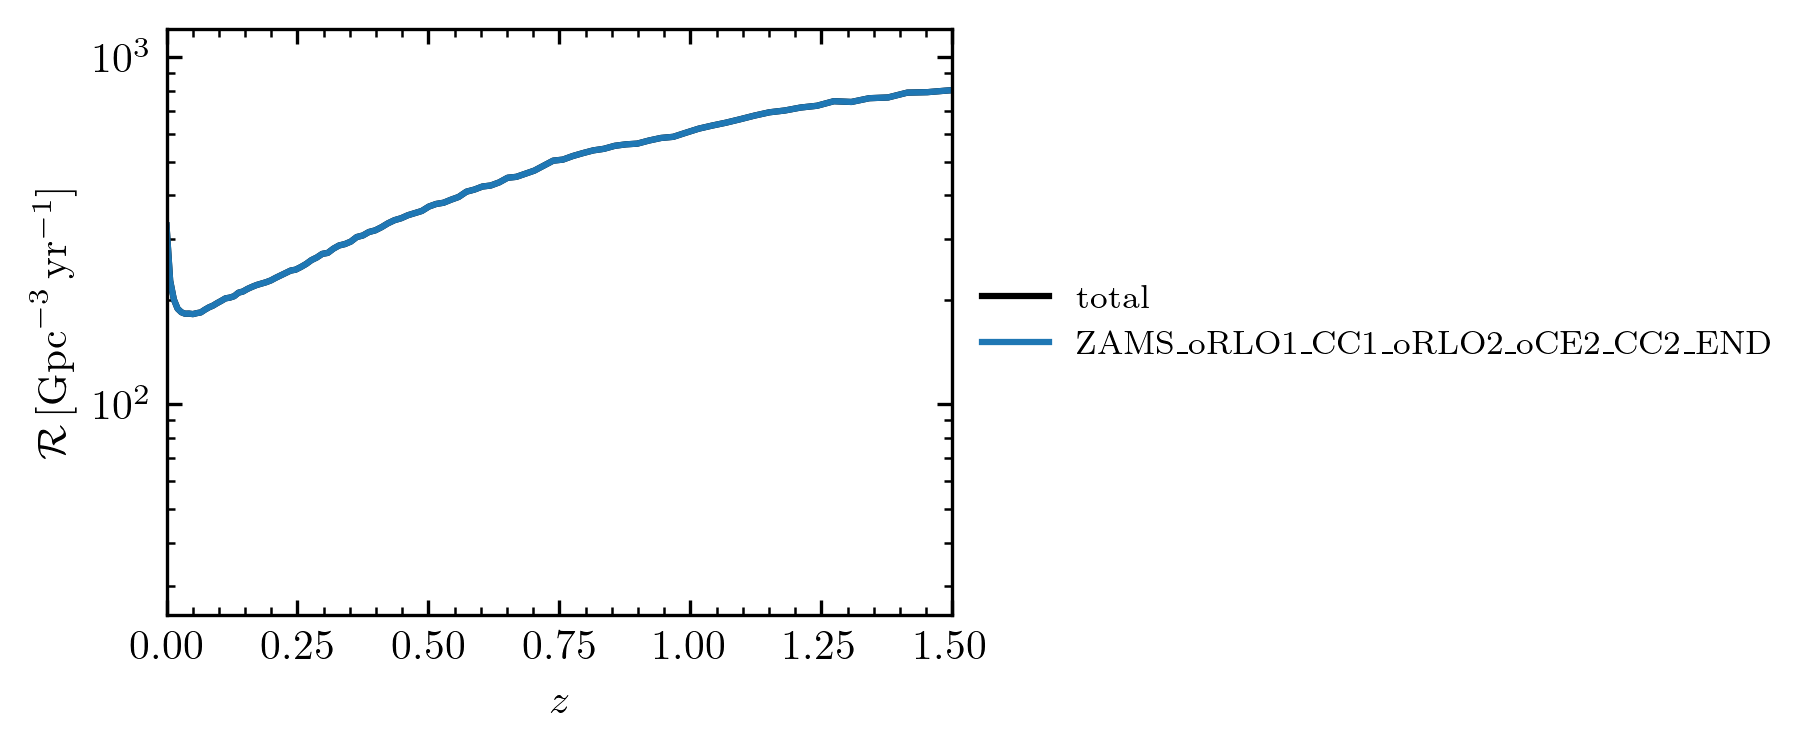

In [22]:
rates.plot_intrinsic_rate(channels = True, xlim=(0,1.5), show = True)

#fig = plt.gcf()
#fig.savefig("BBH_merger_rate_intrinsic.png", dpi=300)
#plt.close(fig)

In [23]:
from posydon.popsyn.transient_select_funcs import DCO_detectability
from posydon.popsyn.synthetic_population import Rates

rates = Rates('../Generated_Tuto_Data/Zsun_BBH_contact.h5', 'BBH', 'IllustrisTNG',)

def DCO_wrapper(transient_chunk, z_events_chunk, weights_chunk):
    sensitivity = 'design_H1L1V1'
    return DCO_detectability(sensitivity, transient_chunk, z_events_chunk, weights_chunk, verbose=False)

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [24]:
# WE also give it a name, which is used as an identifier i nthe file

rates.calculate_observable_population(DCO_wrapper,'design_H1L1V1')

In [25]:
# We can now access this observabel population 

rates.observable_population('design_H1L1V1')

,0,1,2,3,4,5,6,7,8,9,...,128,129,130,131,132,133,134,135,136,137
0,0.0,0.0,0.0,0.039758,0.194018,0.468299,0.863999,1.396155,2.076637,2.921197,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0


#### 4. Visualize the BBH population properties 

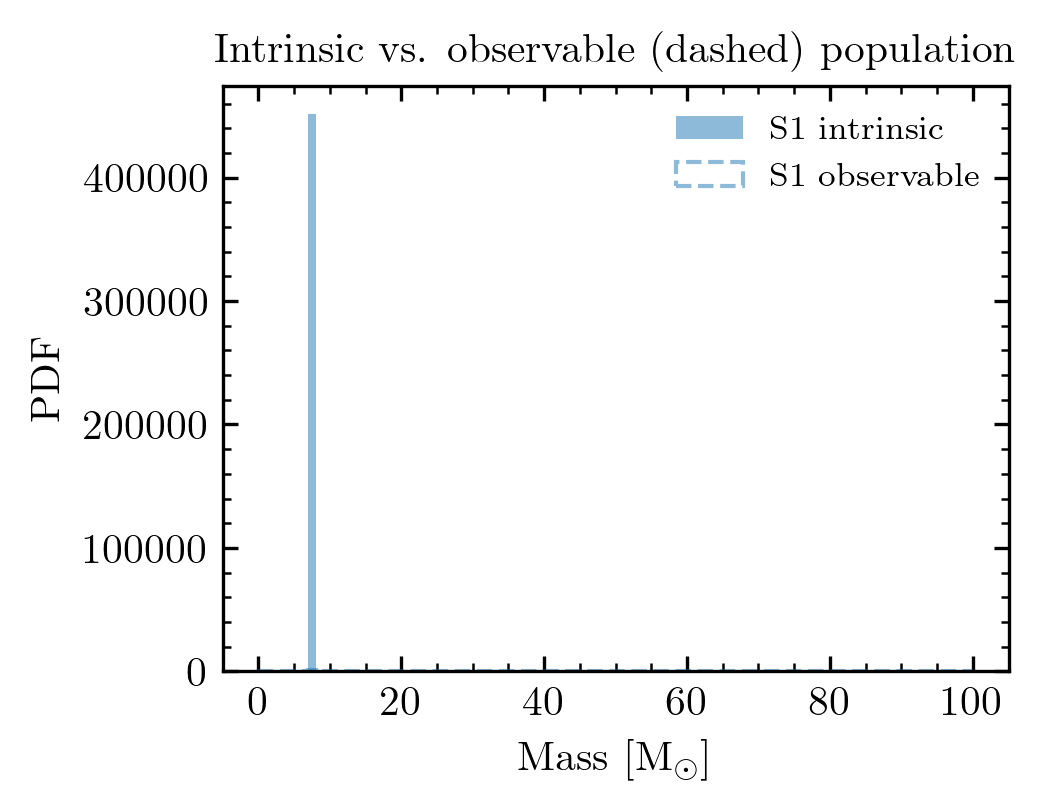

In [36]:
bins = np.linspace(0,100,101)
fig, ax = plt.subplots(1,1)

rates.plot_hist_properties('S1_mass', intrinsic= True, observable='design_H1L1V1', normalize = True,
                           bins = bins, ax = ax, label = 'S1', show = False)

ax.set_ylabel('PDF')
ax.set_xlabel('Mass [M$_\odot$]')
ax.legend()
plt.show()
